# FraudTrace - Exploratory Data Analysis

Exploration of **1,000,000 synthetic banking transactions** stored in the `fraudtrace` MSSQL database (star schema: `fact_transactions` + 5 dimensions).

**Approach:**
- Full-population **aggregates** are computed in SQL (exact, no sampling error)
- A **100K-row enriched sample** is used for row-level distribution plots
- Charts built with Matplotlib + Seaborn


In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import pyodbc

warnings.filterwarnings('ignore', message='pandas only supports SQLAlchemy.*')
warnings.filterwarnings('ignore', category=FutureWarning)

sns.set_theme(style='whitegrid')
RED = '#b91c1c'
BLUE = '#1e40af'

server = os.environ.get('DB_SERVER', r'localhost\SQLEXPRESS02')
driver = os.environ.get('DB_DRIVER', '{ODBC Driver 17 for SQL Server}')
conn = pyodbc.connect(
    f'DRIVER={driver};SERVER={server};DATABASE=fraudtrace;Trusted_Connection=yes;',
    timeout=30
)


def query(sql):
    return pd.read_sql(sql, conn)


print('Connected to fraudtrace database')

Connected to fraudtrace database


## 1. Database Overview

In [2]:
overview = query("""
    SELECT
        COUNT(*) AS total_transactions,
        SUM(CASE WHEN is_fraud = 1 THEN 1 ELSE 0 END) AS fraud_transactions,
        CAST(100.0 * SUM(CASE WHEN is_fraud = 1 THEN 1 ELSE 0 END) / COUNT(*) AS DECIMAL(5,2)) AS fraud_rate_pct
    FROM fact_transactions
""")
dim_counts = query("""
    SELECT 'customers' AS table_name, COUNT(*) AS rows FROM dim_customers
    UNION ALL SELECT 'accounts', COUNT(*) FROM dim_accounts
    UNION ALL SELECT 'devices', COUNT(*) FROM dim_devices
    UNION ALL SELECT 'locations', COUNT(*) FROM dim_locations
    UNION ALL SELECT 'time', COUNT(*) FROM dim_time
""")
display(dim_counts)
overview

,table_name,rows
0,customers,10000
1,accounts,15000
2,devices,20000
3,locations,500
4,time,1095


,total_transactions,fraud_transactions,fraud_rate_pct
0,1000000,29907,2.99


## 2. Enriched Sample for Row-Level Exploration

`TOP 100000` grabs a fast slice joined to customers and devices for exploratory plots.

In [3]:
df = query("""
    SELECT TOP 100000
        t.transaction_id, t.amount, t.transaction_type, t.channel,
        t.is_fraud, t.fraud_type, t.transaction_time,
        DATEPART(HOUR, t.transaction_time) AS hour,
        c.country, c.age, c.gender, c.risk_profile,
        d.device_type, d.operating_system
    FROM fact_transactions t
    JOIN dim_customers c ON t.customer_id = c.customer_id
    JOIN dim_devices d ON t.device_id = d.device_id
""")
df['label'] = np.where(df['is_fraud'], 'Fraud', 'Legitimate')
print(f'Sample size: {len(df):,} rows ({int(df.is_fraud.sum()):,} fraud)')
df.info()

Sample size: 100,000 rows (3,002 fraud)
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 15 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   transaction_id    100000 non-null  int64         
 1   amount            100000 non-null  float64       
 2   transaction_type  100000 non-null  str           
 3   channel           100000 non-null  str           
 4   is_fraud          100000 non-null  bool          
 5   fraud_type        3002 non-null    str           
 6   transaction_time  100000 non-null  datetime64[us]
 7   hour              100000 non-null  int64         
 8   country           100000 non-null  str           
 9   age               100000 non-null  int64         
 10  gender            100000 non-null  str           
 11  risk_profile      100000 non-null  str           
 12  device_type       100000 non-null  str           
 13  operating_system  100000 non-nu

In [4]:
df.describe(include='all')

,transaction_id,amount,transaction_type,channel,is_fraud,fraud_type,transaction_time,hour,country,age,gender,risk_profile,device_type,operating_system,label
count,100000.000000,100000.000000,100000,100000,100000,3002,100000,100000.000000,100000,100000.000000,100000,100000,100000,100000,100000
unique,NaN,NaN,6,6,2,6,NaN,NaN,8,NaN,3,4,3,6,2
top,NaN,NaN,PAYMENT,MOBILE,False,UNUSUAL_AMOUNT,NaN,NaN,Nigeria,NaN,MALE,LOW,MOBILE,Android,Legitimate
freq,NaN,NaN,29425,38543,96998,634,NaN,NaN,25480,NaN,49050,51569,70488,53521,96998
mean,50000.500000,977.214120,NaN,NaN,NaN,NaN,2025-02-19 07:26:20.883029,13.925300,NaN,38.190090,NaN,NaN,NaN,NaN,NaN
min,1.000000,3.420000,NaN,NaN,NaN,NaN,2023-08-22 01:23:25,0.000000,NaN,18.000000,NaN,NaN,NaN,NaN,NaN
25%,25000.750000,145.700000,NaN,NaN,NaN,NaN,2024-05-21 14:17:13.250000,10.000000,NaN,29.000000,NaN,NaN,NaN,NaN,NaN
50%,50000.500000,320.995000,NaN,NaN,NaN,NaN,2025-02-18 20:19:18,14.000000,NaN,38.000000,NaN,NaN,NaN,NaN,NaN
75%,75000.250000,753.395000,NaN,NaN,NaN,NaN,2025-11-20 15:06:10.250000,18.000000,NaN,47.000000,NaN,NaN,NaN,NaN,NaN
max,100000.000000,200270.450000,NaN,NaN,NaN,NaN,2026-08-20 23:55:57,23.000000,NaN,90.000000,NaN,NaN,NaN,NaN,NaN


## 3. Fraud Pattern Breakdown

The generator injects six rule-based fraud patterns. Which ones dominate?

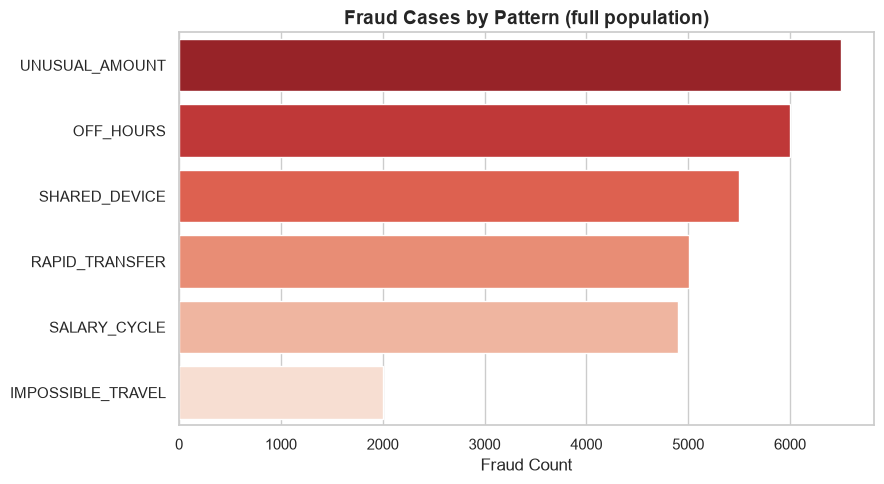

,fraud_type,fraud_count
0,UNUSUAL_AMOUNT,6500
1,OFF_HOURS,6000
2,SHARED_DEVICE,5500
3,RAPID_TRANSFER,5004
4,SALARY_CYCLE,4903
5,IMPOSSIBLE_TRAVEL,2000


In [5]:
patterns = query("""
    SELECT fraud_type, COUNT(*) AS fraud_count
    FROM fact_transactions
    WHERE is_fraud = 1
    GROUP BY fraud_type
    ORDER BY fraud_count DESC
""")

plt.figure(figsize=(9, 5))
sns.barplot(data=patterns, x='fraud_count', y='fraud_type', palette='Reds_r')
plt.title('Fraud Cases by Pattern (full population)', fontsize=14, fontweight='bold')
plt.xlabel('Fraud Count')
plt.ylabel('')
plt.tight_layout()
plt.show()

patterns

## 4. Temporal Patterns

### 4.1 Hour of Day - the off-hours signature

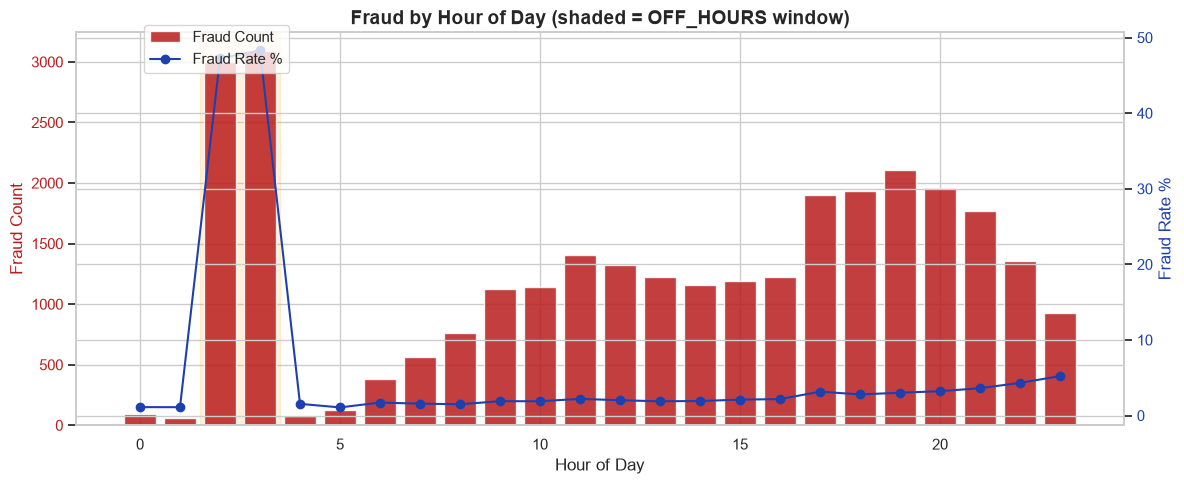

Off-hours (02:00-03:00) fraud rate: 47.8% vs overall baseline 3.0%


In [6]:
hourly = query("""
    SELECT
        DATEPART(HOUR, transaction_time) AS hour,
        COUNT(*) AS total_transactions,
        SUM(CASE WHEN is_fraud = 1 THEN 1 ELSE 0 END) AS fraud_count,
        CAST(100.0 * SUM(CASE WHEN is_fraud = 1 THEN 1 ELSE 0 END) / COUNT(*) AS DECIMAL(5,2)) AS fraud_rate_pct
    FROM fact_transactions
    GROUP BY DATEPART(HOUR, transaction_time)
    ORDER BY hour
""")

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.axvspan(1.5, 3.5, color='orange', alpha=0.15)
ax1.bar(hourly['hour'], hourly['fraud_count'], color=RED, alpha=0.85, label='Fraud Count')
ax1.set_xlabel('Hour of Day')
ax1.set_ylabel('Fraud Count', color=RED)
ax1.tick_params(axis='y', labelcolor=RED)

ax2 = ax1.twinx()
ax2.plot(hourly['hour'], hourly['fraud_rate_pct'].astype(float), color=BLUE, marker='o', label='Fraud Rate %')
ax2.set_ylabel('Fraud Rate %', color=BLUE)
ax2.tick_params(axis='y', labelcolor=BLUE)

handles = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
fig.legend(handles, [h.get_label() for h in handles], loc='upper left', bbox_to_anchor=(0.12, 0.95))
plt.title('Fraud by Hour of Day (shaded = OFF_HOURS window)', fontsize=14, fontweight='bold')
fig.tight_layout()
plt.show()

off_hours = hourly.loc[hourly['hour'].isin([2, 3]), 'fraud_rate_pct'].astype(float).mean()
baseline = overview['fraud_rate_pct'].iloc[0]
print(f'Off-hours (02:00-03:00) fraud rate: {off_hours:.1f}% vs overall baseline {float(baseline):.1f}%')

### 4.2 Day of Week

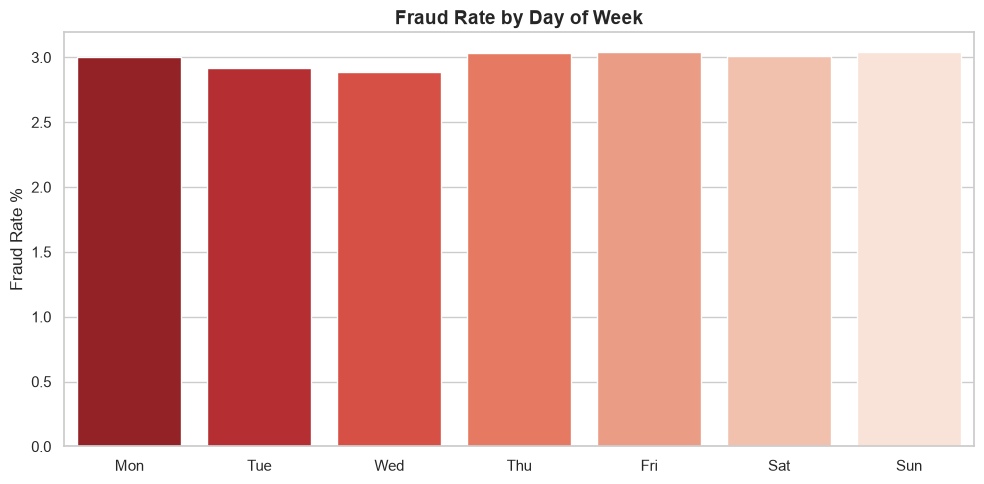

Day-of-week range: 2.89% - 3.04% (no meaningful weekly cycle)


In [7]:
dow = query("""
    SELECT
        CASE dt.day_of_week
            WHEN 1 THEN 'Mon' WHEN 2 THEN 'Tue' WHEN 3 THEN 'Wed' WHEN 4 THEN 'Thu'
            WHEN 5 THEN 'Fri' WHEN 6 THEN 'Sat' WHEN 7 THEN 'Sun'
        END AS day,
        COUNT(*) AS total_transactions,
        SUM(CASE WHEN ft.is_fraud = 1 THEN 1 ELSE 0 END) AS fraud_count,
        CAST(100.0 * SUM(CASE WHEN ft.is_fraud = 1 THEN 1 ELSE 0 END) / COUNT(*) AS DECIMAL(5,2)) AS fraud_rate_pct
    FROM fact_transactions ft
    JOIN dim_time dt ON ft.time_key = dt.time_key
    GROUP BY dt.day_of_week
    ORDER BY dt.day_of_week
""")

plt.figure(figsize=(10, 5))
sns.barplot(data=dow, x='day', y=dow['fraud_rate_pct'].astype(float), palette='Reds_r')
plt.title('Fraud Rate by Day of Week', fontsize=14, fontweight='bold')
plt.ylabel('Fraud Rate %')
plt.xlabel('')
plt.tight_layout()
plt.show()

print(f'Day-of-week range: {dow["fraud_rate_pct"].astype(float).min():.2f}% - '
      f'{dow["fraud_rate_pct"].astype(float).max():.2f}% (no meaningful weekly cycle)')

### 4.3 Monthly Trend

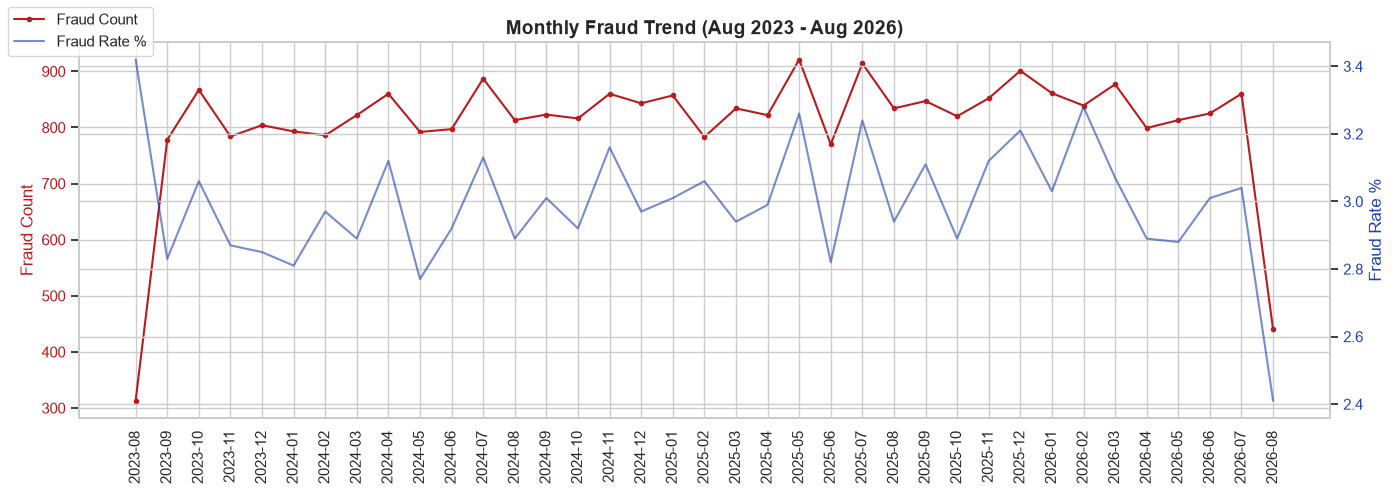

Monthly fraud count range: 313 - 921 (stable over time)


In [8]:
monthly = query("""
    SELECT
        dt.[year],
        dt.[month],
        COUNT(*) AS total_transactions,
        SUM(CASE WHEN ft.is_fraud = 1 THEN 1 ELSE 0 END) AS fraud_count,
        CAST(100.0 * SUM(CASE WHEN ft.is_fraud = 1 THEN 1 ELSE 0 END) / COUNT(*) AS DECIMAL(5,2)) AS fraud_rate_pct
    FROM fact_transactions ft
    JOIN dim_time dt ON ft.time_key = dt.time_key
    GROUP BY dt.[year], dt.[month]
    ORDER BY dt.[year], dt.[month]
""")
monthly['period'] = monthly['year'].astype(int).astype(str) + '-' + monthly['month'].astype(int).astype(str).str.zfill(2)

fig, ax1 = plt.subplots(figsize=(14, 5))
ax1.plot(monthly['period'], monthly['fraud_count'], color=RED, marker='o', markersize=3, label='Fraud Count')
ax1.set_ylabel('Fraud Count', color=RED)
ax1.tick_params(axis='y', labelcolor=RED)
ax1.tick_params(axis='x', rotation=90)

ax2 = ax1.twinx()
ax2.plot(monthly['period'], monthly['fraud_rate_pct'].astype(float), color=BLUE, alpha=0.6, label='Fraud Rate %')
ax2.set_ylabel('Fraud Rate %', color=BLUE)
ax2.tick_params(axis='y', labelcolor=BLUE)

handles = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
fig.legend(handles, [h.get_label() for h in handles], loc='upper left')
plt.title('Monthly Fraud Trend (Aug 2023 - Aug 2026)', fontsize=14, fontweight='bold')
fig.tight_layout()
plt.show()

print(f'Monthly fraud count range: {monthly["fraud_count"].min():,} - {monthly["fraud_count"].max():,} (stable over time)')

### 4.4 Salary Days (25th-28th)

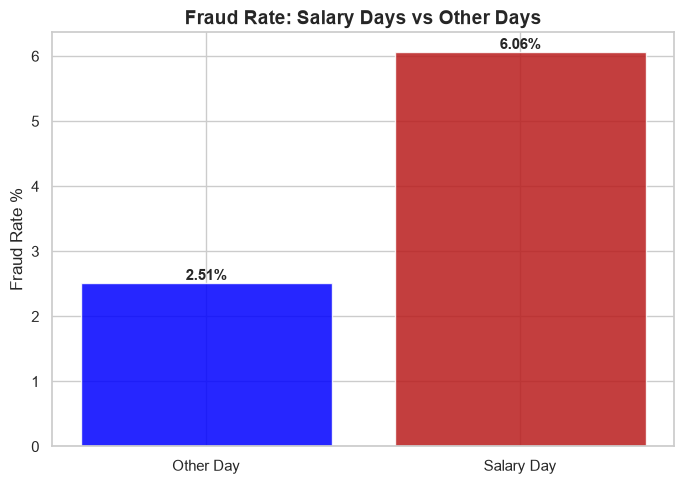

Salary days run 6.06% vs 2.51% on other days - a 2.4x multiplier


In [9]:
salary = query("""
    SELECT
        CASE WHEN dt.is_salary_day = 1 THEN 'Salary Day' ELSE 'Other Day' END AS day_type,
        COUNT(*) AS transactions,
        SUM(CASE WHEN ft.is_fraud = 1 THEN 1 ELSE 0 END) AS fraud_count,
        CAST(100.0 * SUM(CASE WHEN ft.is_fraud = 1 THEN 1 ELSE 0 END) / COUNT(*) AS DECIMAL(5,2)) AS fraud_rate_pct
    FROM fact_transactions ft
    JOIN dim_time dt ON ft.time_key = dt.time_key
    GROUP BY dt.is_salary_day
""")

plt.figure(figsize=(7, 5))
colors = ['blue' if t == 'Other Day' else RED for t in salary['day_type']]
bars = plt.bar(salary['day_type'], salary['fraud_rate_pct'].astype(float), color=colors, alpha=0.85)
for bar, rate in zip(bars, salary['fraud_rate_pct'].astype(float)):
    plt.text(bar.get_x() + bar.get_width() / 2, rate, f'{rate:.2f}%', ha='center', va='bottom',
             fontsize=11, fontweight='bold')
plt.title('Fraud Rate: Salary Days vs Other Days', fontsize=14, fontweight='bold')
plt.ylabel('Fraud Rate %')
plt.tight_layout()
plt.show()

salary_rate = float(salary.loc[salary['day_type'] == 'Salary Day', 'fraud_rate_pct'].iloc[0])
other_rate = float(salary.loc[salary['day_type'] == 'Other Day', 'fraud_rate_pct'].iloc[0])
print(f'Salary days run {salary_rate:.2f}% vs {other_rate:.2f}% on other days - a {salary_rate / other_rate:.1f}x multiplier')

## 5. Amount Analysis

In [10]:
amounts = query("""
    SELECT
        CASE WHEN is_fraud = 1 THEN 'Fraud' ELSE 'Legitimate' END AS class,
        COUNT(*) AS transaction_count,
        CAST(AVG(amount) AS DECIMAL(18,2)) AS average_amount,
        CAST(SUM(amount) AS DECIMAL(18,2)) AS total_amount
    FROM fact_transactions
    GROUP BY is_fraud
""")
display(amounts)

ratio = (amounts.loc[amounts['class'] == 'Fraud', 'average_amount'].iloc[0]
         / amounts.loc[amounts['class'] == 'Legitimate', 'average_amount'].iloc[0])
fraud_total = amounts.loc[amounts['class'] == 'Fraud', 'total_amount'].iloc[0]
grand_total = amounts['total_amount'].sum()
print(f'Average fraudulent amount is {float(ratio):.1f}x the legitimate average')
print(f'Fraud accounts for {100 * float(fraud_total / grand_total):.1f}% of all transaction value '
      f'(vs {float(baseline):.1f}% of volume)')

,class,transaction_count,average_amount,total_amount
0,Legitimate,970093,710.81,6.895509e+08
1,Fraud,29907,9705.13,2.902514e+08


Average fraudulent amount is 13.7x the legitimate average
Fraud accounts for 29.6% of all transaction value (vs 3.0% of volume)


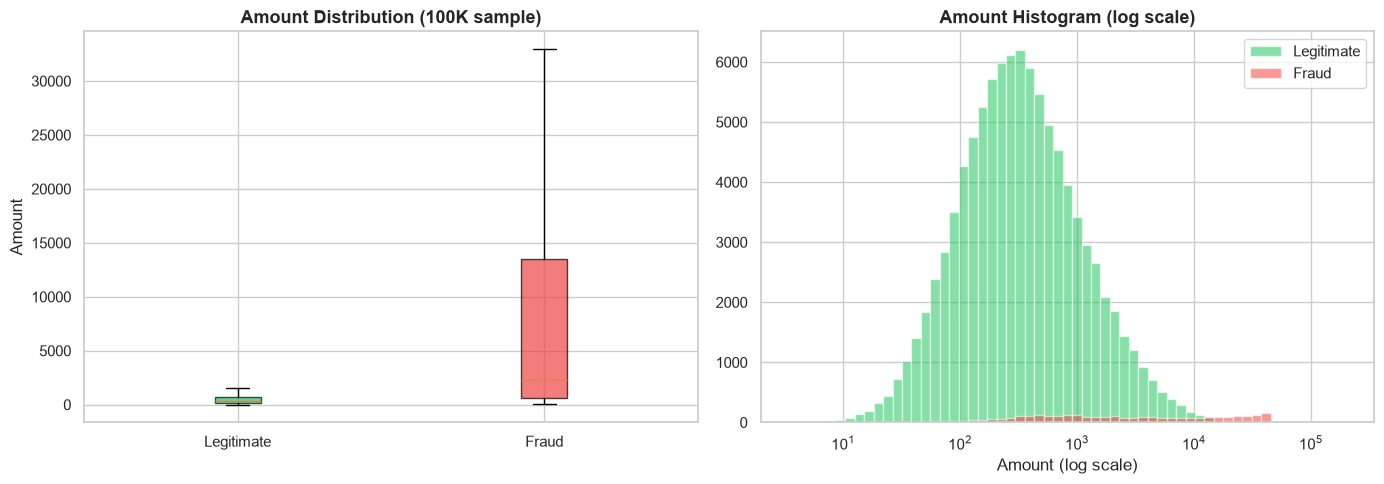

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

class_colors = {'Legitimate': '#22c55e', 'Fraud': '#ef4444'}
grouped = [df.loc[df['label'] == lbl, 'amount'] for lbl in class_colors]

boxes = axes[0].boxplot(grouped, showfliers=False, patch_artist=True)
for patch, lbl in zip(boxes['boxes'], class_colors):
    patch.set_facecolor(class_colors[lbl])
    patch.set_alpha(0.7)
axes[0].set_xticklabels(list(class_colors))
axes[0].set_title('Amount Distribution (100K sample)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('')
axes[0].set_ylabel('Amount')

bins = np.logspace(np.log10(df['amount'].min()), np.log10(df['amount'].max()), 60)
for lbl, colr in class_colors.items():
    axes[1].hist(df.loc[df['label'] == lbl, 'amount'], bins=bins,
                 alpha=0.55, color=colr, label=lbl)
axes[1].set_xscale('log')
axes[1].legend(title='')
axes[1].set_title('Amount Histogram (log scale)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Amount (log scale)')

plt.tight_layout()
plt.show()

## 6. Categorical Dimensions

### 6.1 Channel and Transaction Type

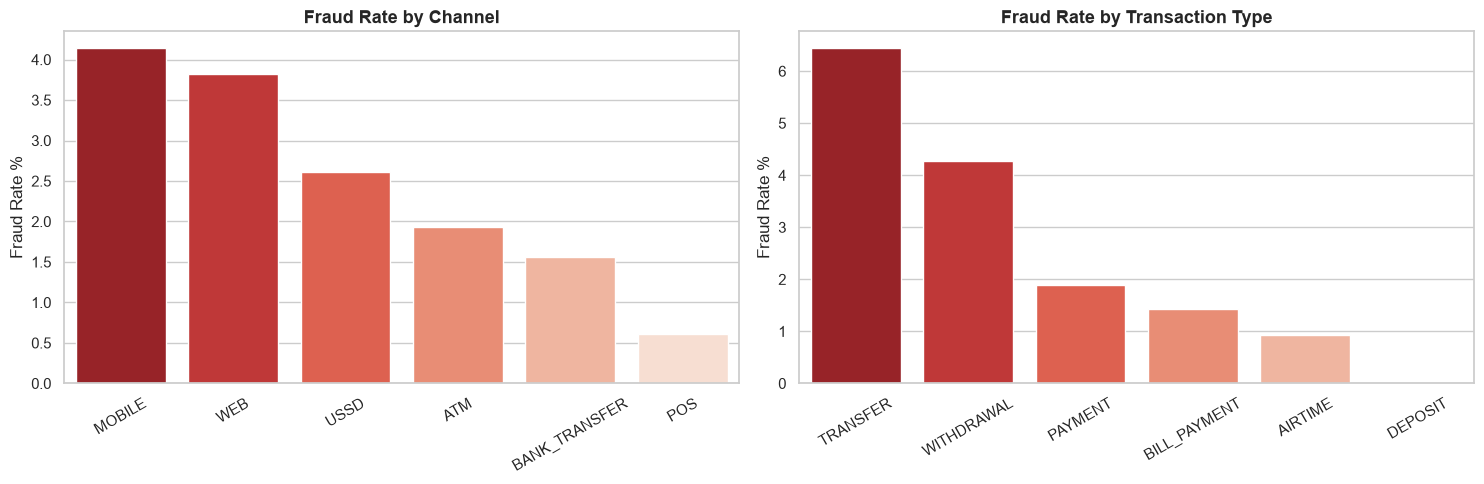

Highest-risk channel: MOBILE at 4.14%, lowest: POS at 0.61%
Transaction types with zero fraud: DEPOSIT


In [12]:
channel_rates = query("""
    SELECT
        channel,
        COUNT(*) AS transactions,
        SUM(CASE WHEN is_fraud = 1 THEN 1 ELSE 0 END) AS fraud_count,
        CAST(100.0 * SUM(CASE WHEN is_fraud = 1 THEN 1 ELSE 0 END) / COUNT(*) AS DECIMAL(5,2)) AS fraud_rate_pct
    FROM fact_transactions
    GROUP BY channel
    ORDER BY fraud_rate_pct DESC
""")
type_rates = query("""
    SELECT
        transaction_type,
        COUNT(*) AS transactions,
        SUM(CASE WHEN is_fraud = 1 THEN 1 ELSE 0 END) AS fraud_count,
        CAST(100.0 * SUM(CASE WHEN is_fraud = 1 THEN 1 ELSE 0 END) / COUNT(*) AS DECIMAL(5,2)) AS fraud_rate_pct
    FROM fact_transactions
    GROUP BY transaction_type
    ORDER BY fraud_rate_pct DESC
""")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(data=channel_rates, x='channel', y=channel_rates['fraud_rate_pct'].astype(float),
            palette='Reds_r', ax=axes[0])
axes[0].set_title('Fraud Rate by Channel', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Fraud Rate %')
axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=30)

sns.barplot(data=type_rates, x='transaction_type', y=type_rates['fraud_rate_pct'].astype(float),
            palette='Reds_r', ax=axes[1])
axes[1].set_title('Fraud Rate by Transaction Type', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Fraud Rate %')
axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

print(f'Highest-risk channel: {channel_rates.iloc[0]["channel"]} at '
      f'{float(channel_rates.iloc[0]["fraud_rate_pct"]):.2f}%, lowest: '
      f'{channel_rates.iloc[-1]["channel"]} at {float(channel_rates.iloc[-1]["fraud_rate_pct"]):.2f}%')
zero_types = type_rates.loc[type_rates['fraud_count'] == 0, 'transaction_type'].tolist()
print(f'Transaction types with zero fraud: {", ".join(zero_types) if zero_types else "none"}')

### 6.2 Geography and Customer Attributes

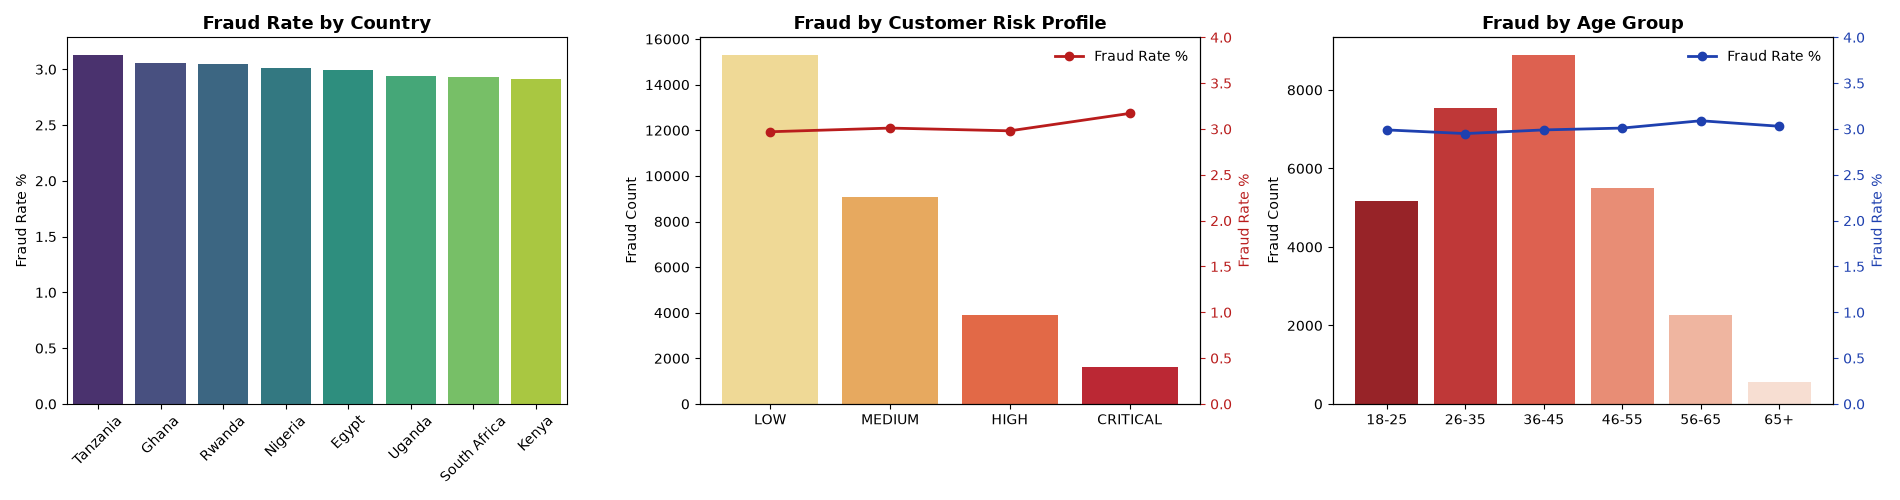

All three dimensions stay in a narrow band around the ~3% baseline - demographics carry little signal here; behavior (time, amount, velocity) does.


In [13]:
from pathlib import Path

exports_dir = Path('data') / 'exports'
if not exports_dir.exists():
    exports_dir = Path('..') / 'data' / 'exports'

country_rates = pd.read_csv(exports_dir / 'fraud_by_country.csv',
                            encoding='utf-8-sig')
country_rates = country_rates.rename(columns={'total_transactions': 'transactions'})
country_rates = country_rates.sort_values('fraud_rate_pct', ascending=False)

demographics = pd.read_csv(exports_dir / 'fraud_by_demographics.csv',
                           encoding='utf-8-sig')

risk_rates = (demographics.groupby('risk_profile', as_index=False)
              .agg(transactions=('total_transactions', 'sum'),
                   fraud_count=('fraud_count', 'sum')))
risk_rates['fraud_rate_pct'] = (100 * risk_rates['fraud_count']
                                / risk_rates['transactions']).round(2)
risk_order = ['LOW', 'MEDIUM', 'HIGH', 'CRITICAL']
risk_rates['risk_profile'] = pd.Categorical(risk_rates['risk_profile'], categories=risk_order, ordered=True)
risk_rates = risk_rates.sort_values('risk_profile')

age_rates = (demographics.groupby('age_group', as_index=False)
             .agg(transactions=('total_transactions', 'sum'),
                  fraud_count=('fraud_count', 'sum')))
age_rates['fraud_rate_pct'] = (100 * age_rates['fraud_count']
                               / age_rates['transactions']).round(2)
age_groups = ['18-25', '26-35', '36-45', '46-55', '56-65', '65+']
age_rates['age_group'] = pd.Categorical(age_rates['age_group'], categories=age_groups, ordered=True)
age_rates = age_rates.sort_values('age_group')

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

sns.barplot(data=country_rates, x='country', y=country_rates['fraud_rate_pct'].astype(float),
            palette='viridis', ax=axes[0])
axes[0].set_title('Fraud Rate by Country', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Fraud Rate %')
axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=45)

sns.barplot(data=risk_rates, x='risk_profile', y=risk_rates['fraud_count'].astype(int),
            palette='YlOrRd', ax=axes[1])
axes[1].set_title('Fraud by Customer Risk Profile', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Fraud Count')
axes[1].set_xlabel('')
risk_ax = axes[1].twinx()
risk_ax.plot(range(len(risk_rates)), risk_rates['fraud_rate_pct'].astype(float),
             color=RED, marker='o', linewidth=2, label='Fraud Rate %')
risk_ax.set_ylabel('Fraud Rate %', color=RED)
risk_ax.set_ylim(0, 4)
risk_ax.tick_params(axis='y', colors=RED)
risk_ax.legend(loc='upper right', frameon=False)

sns.barplot(data=age_rates, x='age_group', y=age_rates['fraud_count'].astype(int),
            palette='Reds_r', ax=axes[2])
axes[2].set_title('Fraud by Age Group', fontsize=13, fontweight='bold')
axes[2].set_ylabel('Fraud Count')
axes[2].set_xlabel('')
age_ax = axes[2].twinx()
age_ax.plot(range(len(age_rates)), age_rates['fraud_rate_pct'].astype(float),
            color=BLUE, marker='o', linewidth=2, label='Fraud Rate %')
age_ax.set_ylabel('Fraud Rate %', color=BLUE)
age_ax.set_ylim(0, 4)
age_ax.tick_params(axis='y', colors=BLUE)
age_ax.legend(loc='upper right', frameon=False)

plt.tight_layout()
plt.show()

print('All three dimensions stay in a narrow band around the ~3% baseline - '
      'demographics carry little signal here; behavior (time, amount, velocity) does.')

### 6.3 Devices

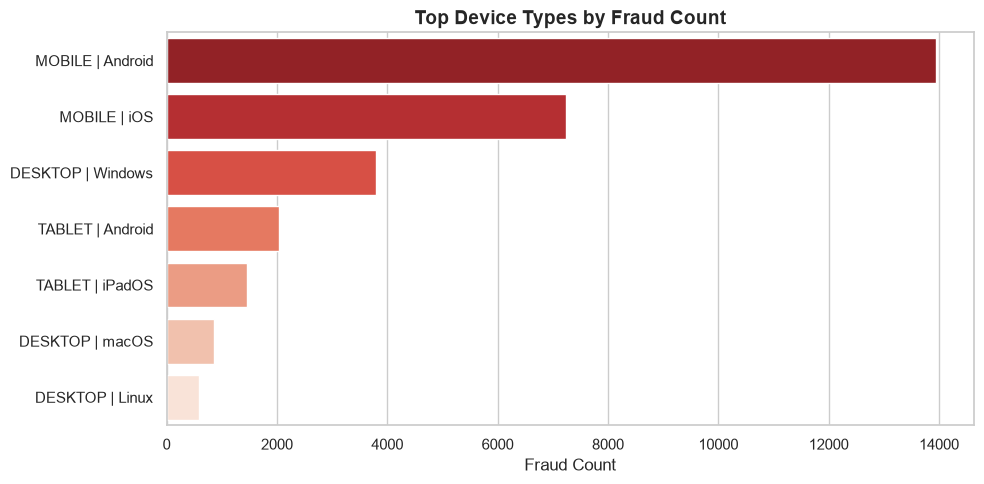

,device,transactions,fraud_count
0,MOBILE | Android,466081,13937
1,MOBILE | iOS,239227,7232
2,DESKTOP | Windows,123605,3802
3,TABLET | Android,68145,2035
4,TABLET | iPadOS,51974,1457
5,DESKTOP | macOS,30135,866
6,DESKTOP | Linux,20833,578


In [14]:
devices = query("""
    SELECT TOP 10
        CONCAT(d.device_type, ' | ', d.operating_system) AS device,
        COUNT(*) AS transactions,
        SUM(CASE WHEN t.is_fraud = 1 THEN 1 ELSE 0 END) AS fraud_count
    FROM fact_transactions t
    JOIN dim_devices d ON t.device_id = d.device_id
    GROUP BY CONCAT(d.device_type, ' | ', d.operating_system)
    ORDER BY fraud_count DESC
""")

plt.figure(figsize=(10, 5))
sns.barplot(data=devices, x='fraud_count', y='device', palette='Reds_r')
plt.title('Top Device Types by Fraud Count', fontsize=14, fontweight='bold')
plt.xlabel('Fraud Count')
plt.ylabel('')
plt.tight_layout()
plt.show()

devices

## 7. Cross-Dimension View: Fraud Rate by Hour x Channel

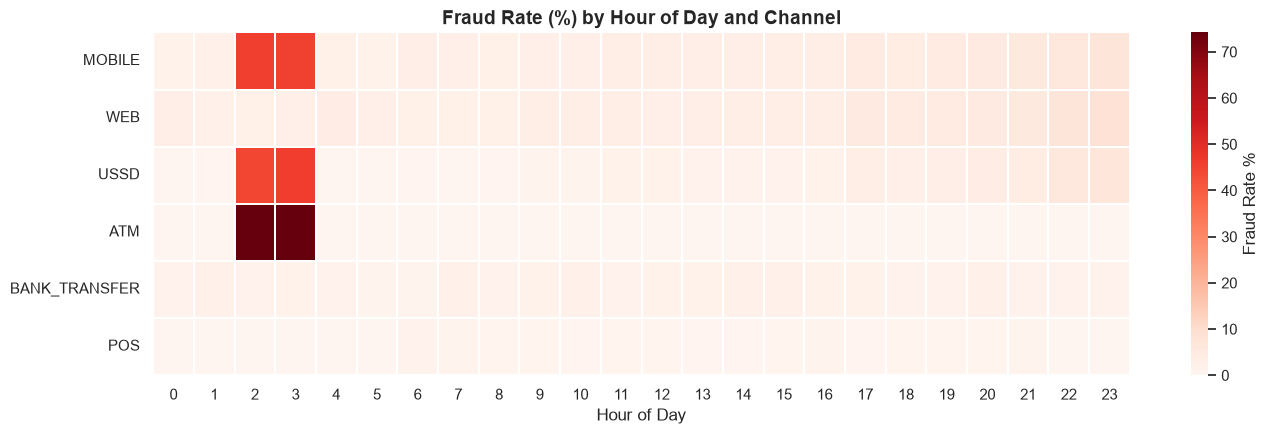

Hottest cell: ATM at hour 02 with 74.2% fraud rate


In [15]:
heat = query("""
    SELECT
        DATEPART(HOUR, transaction_time) AS hour,
        channel,
        COUNT(*) AS total_transactions,
        SUM(CASE WHEN is_fraud = 1 THEN 1 ELSE 0 END) AS fraud_count
    FROM fact_transactions
    GROUP BY DATEPART(HOUR, transaction_time), channel
""")
heat['fraud_rate_pct'] = 100 * heat['fraud_count'] / heat['total_transactions']
pivot = heat.pivot(index='channel', columns='hour', values='fraud_rate_pct').astype(float)

order = channel_rates['channel'].tolist()
pivot = pivot.reindex(order)

plt.figure(figsize=(14, 4.5))
sns.heatmap(pivot, cmap='Reds', linewidths=0.3, linecolor='white',
            cbar_kws={'label': 'Fraud Rate %'})
plt.title('Fraud Rate (%) by Hour of Day and Channel', fontsize=14, fontweight='bold')
plt.xlabel('Hour of Day')
plt.ylabel('')
plt.tight_layout()
plt.savefig('../data/charts/nb_hour_channel_heatmap.png', dpi=160, bbox_inches='tight')
plt.show()

stacked = pivot.stack()
peak = stacked.idxmax()
print(f'Hottest cell: {peak[0]} at hour {int(peak[1]):02d} with {stacked.max():.1f}% fraud rate')

## 8. Top Offending Accounts

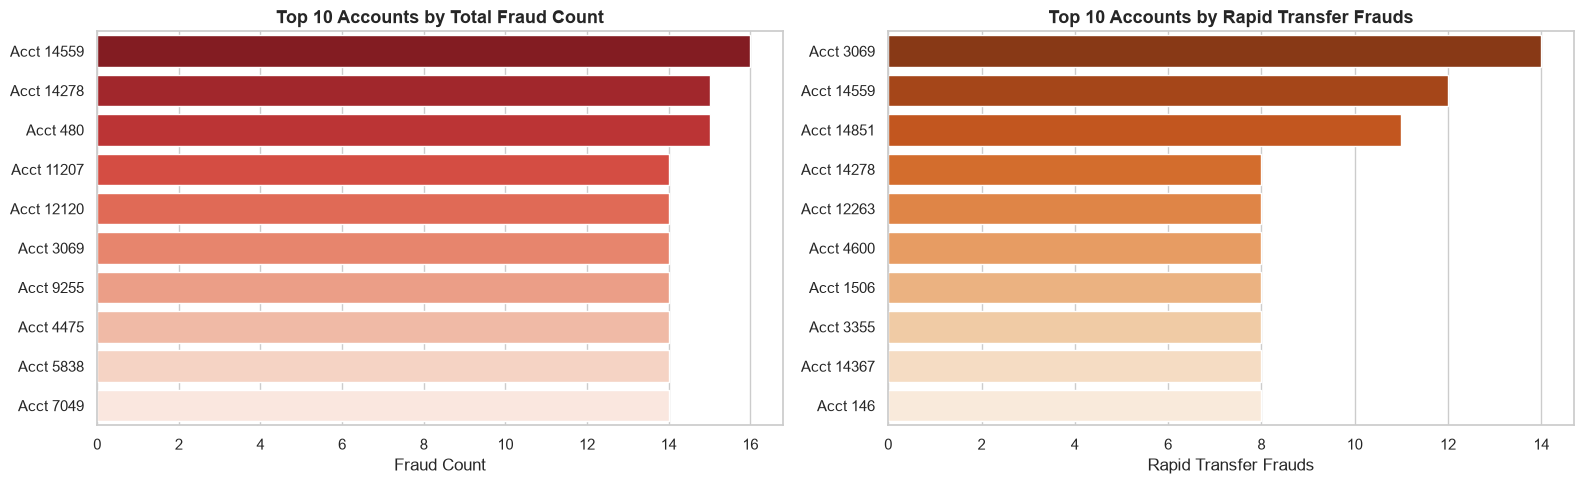

3 of the top-10 fraud accounts also appear in the top-10 rapid-transfer list


In [16]:
top_accounts = query("""
    SELECT TOP 10
        account_id,
        COUNT(*) AS fraud_count,
        CAST(AVG(amount) AS DECIMAL(18,2)) AS avg_fraud_amount
    FROM fact_transactions
    WHERE is_fraud = 1
    GROUP BY account_id
    ORDER BY fraud_count DESC
""")
rapid_accounts = query("""
    SELECT TOP 10
        account_id,
        COUNT(*) AS rapid_transfer_count
    FROM fact_transactions
    WHERE fraud_type = 'RAPID_TRANSFER'
    GROUP BY account_id
    ORDER BY rapid_transfer_count DESC
""")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(data=top_accounts, x='fraud_count',
            y='Acct ' + top_accounts['account_id'].astype(str), palette='Reds_r', ax=axes[0])
axes[0].set_title('Top 10 Accounts by Total Fraud Count', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Fraud Count')
axes[0].set_ylabel('')

sns.barplot(data=rapid_accounts, x='rapid_transfer_count',
            y='Acct ' + rapid_accounts['account_id'].astype(str), palette='Oranges_r', ax=axes[1])
axes[1].set_title('Top 10 Accounts by Rapid Transfer Frauds', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Rapid Transfer Frauds')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

repeat_offenders = set(top_accounts['account_id']) & set(rapid_accounts['account_id'])
print(f'{len(repeat_offenders)} of the top-10 fraud accounts also appear in the top-10 rapid-transfer list')

## Summary

### Key Findings

| # | Finding | Evidence |
|---|---------|----------|
| 1 | **Off-hours (02:00-03:00) is the strongest fraud signal** | ~47-48% fraud rate vs ~1% in adjacent hours |
| 2 | **Salary days multiply fraud risk** | 6.06% vs 2.51% on other days (~2.4x) |
| 3 | **Transfers are the risky movement type** | TRANSFER 6.44% fraud rate; DEPOSIT 0% |
| 4 | **Mobile money is the attack surface** | MOBILE channel 4.14% vs POS 0.61% |
| 5 | **Fraud amounts dwarf legitimate activity** | Avg 9,705 vs 711 (~13.7x); ~29.6% of value from ~3% of volume |
| 6 | **UNUSUAL_AMOUNT is the most common pattern** | 6,500 cases; IMPOSSIBLE_TRAVEL rarest (2,000) |
| 7 | **Demographics are weak predictors** | Country / age / risk-profile rates hover near the 3% baseline |
| 8 | **Repeat offenders concentrate** | Several accounts appear in both top-fraud and top-rapid-transfer rankings |

### Next Steps
- Power BI dashboard connected to the star schema for interactive filtering
- Index performance benchmarking (with vs without indexes)
- Prototype a rules-based scoring model combining top signals (hour, amount ratio, salary window, velocity)


In [17]:
conn.close()
print('Connection closed')

Connection closed
